### Setup & Initialization

In [1]:
# Data Processing & Computer Vision
import cv2 as cv                  
import numpy as np                
import matplotlib.pyplot as plt   

# Machine Learning & Clustering 
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# Deep Learning & Object Detection 
from ultralytics import YOLO

# Initialize Object Detection Model
model = YOLO('yolov8n.pt')

In [2]:
# Importing the Sample Images for Showing the Result of Each Step
images = []
for i in range(1, 11):
    road = cv.imread(f'roads/road{i}.jpg') 
    if road is None:
        road = cv.imread(f'roads/road{i}.png') 
        if road is None:
            print(f"Error loading image roads/road{i}.jpg or roads/road{i}.png")
            continue
    images.append(road)

[ WARN:0@4.871] global loadsave.cpp:278 findDecoder imread_('roads/road1.jpg'): can't open/read file: check file path/integrity
[ WARN:0@4.903] global loadsave.cpp:278 findDecoder imread_('roads/road4.jpg'): can't open/read file: check file path/integrity


### Image Pre-processing

In [3]:
def apply_clahe(image):
    # 1. LAB Color Space Conversion
    lab = cv.cvtColor(image, cv.COLOR_RGB2LAB)

    # 2. Channel Splitting (L: Lightness, A/B: Color)
    l, a, b = cv.split(lab)

    # 3. CLAHE Application on L-Channel
    clahe = cv.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    cl = clahe.apply(l)

    # 4. Merge Channels & Revert to RGB
    limg = cv.merge((cl, a, b))
    final_image = cv.cvtColor(limg, cv.COLOR_LAB2RGB)

    return final_image

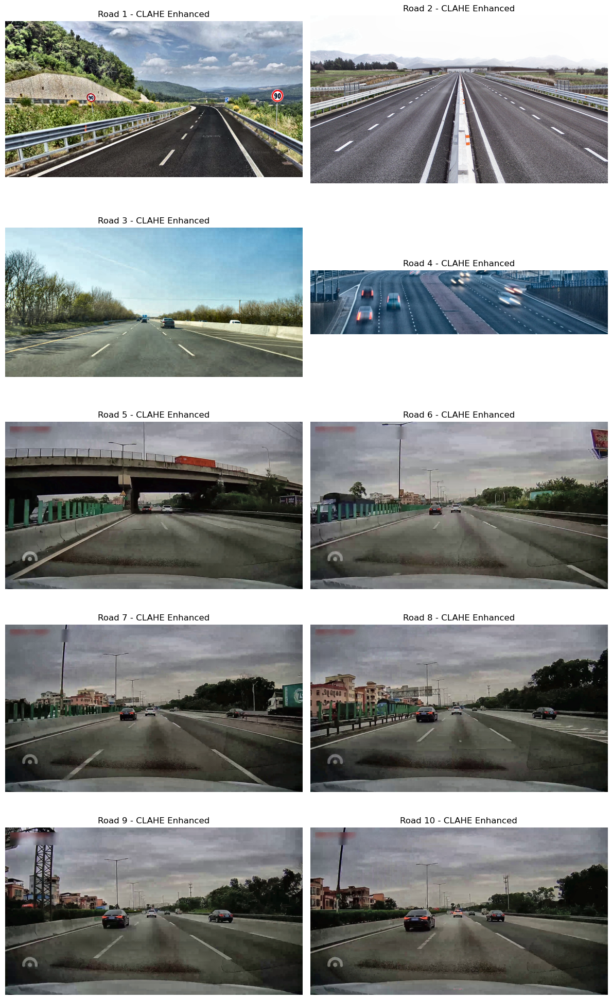

In [4]:
# Visualization of CLAHE Results

plt.figure(figsize=(12, 20))

for i, img in enumerate(images):
    # Apply the function to each image
    rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    clahe_result = apply_clahe(rgb_img)
    
    # Plotting
    plt.subplot(5, 2, i + 1)
    plt.imshow(clahe_result)
    plt.title(f'Road {i+1} - CLAHE Enhanced')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [5]:
def combined_color_gradient_mask(image, sobel_thresh_min=30, white_l_min=200, white_l_max=255, white_s_min=0, white_s_max=255):
    # 1. Texture Smoothing (Bilateral Filter)
    bilateral_image = cv.bilateralFilter(image, d=10, sigmaColor=125, sigmaSpace=75)

    # 2. HLS Color Thresholding (White & Yellow)
    hls = cv.cvtColor(bilateral_image, cv.COLOR_BGR2HLS)
    
    lower_white = np.array([0, white_l_min, white_s_min]) 
    upper_white = np.array([179, white_l_max, white_s_max])
    white_mask = cv.inRange(hls, lower_white, upper_white)
    
    lower_yellow = np.array([10, 0, 100])
    upper_yellow = np.array([40, 255, 255])
    yellow_mask = cv.inRange(hls, lower_yellow, upper_yellow)
    
    color_mask = cv.bitwise_or(white_mask, yellow_mask)
    
    # 3. Morphological Dilation (Closing Gaps)
    kernel = np.ones((5, 5), np.uint8)
    color_mask = cv.dilate(color_mask, kernel, iterations=1)

    # 4. Sobel X-Gradient (Vertical Edge Detection)
    gray = cv.cvtColor(bilateral_image, cv.COLOR_BGR2GRAY)
    sobelx = cv.Sobel(gray, cv.CV_64F, dx=1, dy=0, ksize=3)
    abs_sobelx = np.absolute(sobelx)
    scaled_sobel = np.uint8(255 * abs_sobelx / np.max(abs_sobelx))
    
    sobel_mask = np.zeros_like(scaled_sobel)
    sobel_mask[(scaled_sobel >= sobel_thresh_min) & (scaled_sobel <= 255)] = 255

    # 5. Mask Intersection (Color AND Edge)
    combined_binary_mask = cv.bitwise_and(sobel_mask, color_mask)
    
    # 6. Final Output Generation
    masked_image = np.zeros_like(image)
    masked_image[combined_binary_mask == 255] = [255, 255, 255]
    
    return masked_image

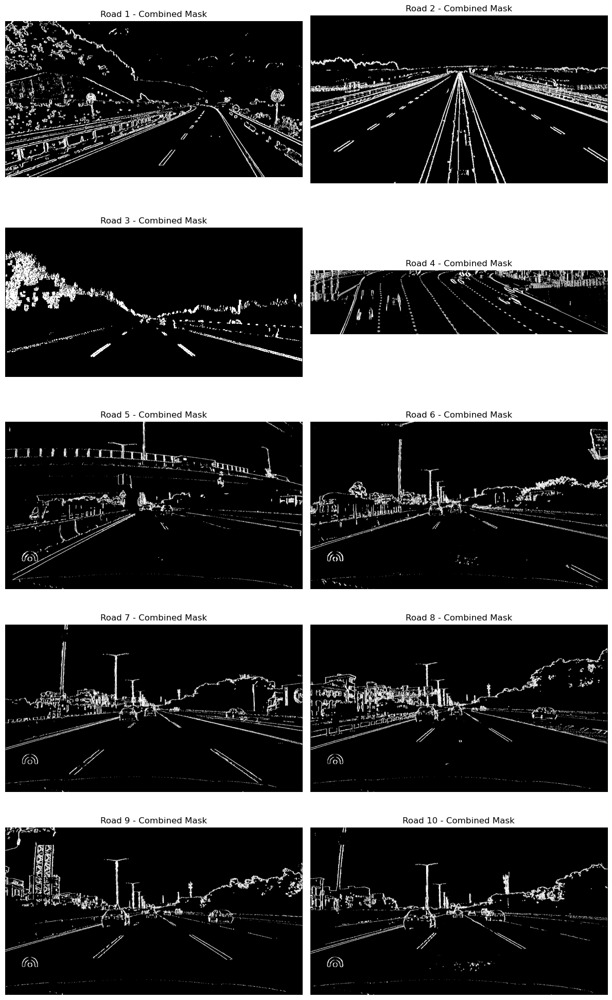

In [6]:
# Visualization of Combined Color & Gradient Mask Results

plt.figure(figsize=(12, 20))

for i, img in enumerate(images):
    # 1. First apply CLAHE to normalize lighting
    rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    uniform_img = apply_clahe(rgb_img)
    
    # 2. Apply the Combined Color & Gradient Mask

    if i < 4:  
        mask_result = combined_color_gradient_mask(
            uniform_img, 
            sobel_thresh_min=10,
            white_l_min=150, 
            white_l_max=255, 
            white_s_min=0
        )
    else: 
        mask_result = combined_color_gradient_mask(
            uniform_img, 
            sobel_thresh_min=7, 
            white_l_min=92, 
            white_l_max=255, 
            white_s_min=0
        )

    
    # Plotting
    plt.subplot(5, 2, i + 1)
    plt.imshow(mask_result, cmap='gray')
    plt.title(f'Road {i+1} - Combined Mask')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
# Canny Is Replaced by Sobel + Color Masking, but here is the original Canny function 

def Canny(image, low_threshold=50, high_threshold=120):
    # 1. Grayscale Conversion
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    
    # 2. Bilateral Filtering (Texture Smoothing)
    bilateral_blurred = cv.bilateralFilter(gray, 9, 75, 75)
    
    # 3. Gaussian Blur (High-Frequency Noise Reduction)
    blurred = cv.GaussianBlur(bilateral_blurred, (5, 5), 0)

    # 4. Canny Edge Detection
    edges = cv.Canny(blurred, low_threshold, high_threshold, apertureSize=3)

    return edges

### ROI & Masking

In [8]:
def blackout_vehicles_from_mask(gray_mask, original_image, yolo_model, conf_threshold=0.30):
    # 1. Duplicate Mask
    clean_mask = gray_mask.copy()
    
    # 2. Detect Vehicles (Cars, Motorcycles, Buses, Trucks)
    results = yolo_model.predict(original_image, classes=[2, 3, 5, 7], conf=conf_threshold, verbose=False)
    
    # 3. Apply Blackout Boxes
    for result in results:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].int().tolist()
            cv.rectangle(clean_mask, (x1, y1), (x2, y2), (0, 0, 0), -1)
            
    return clean_mask

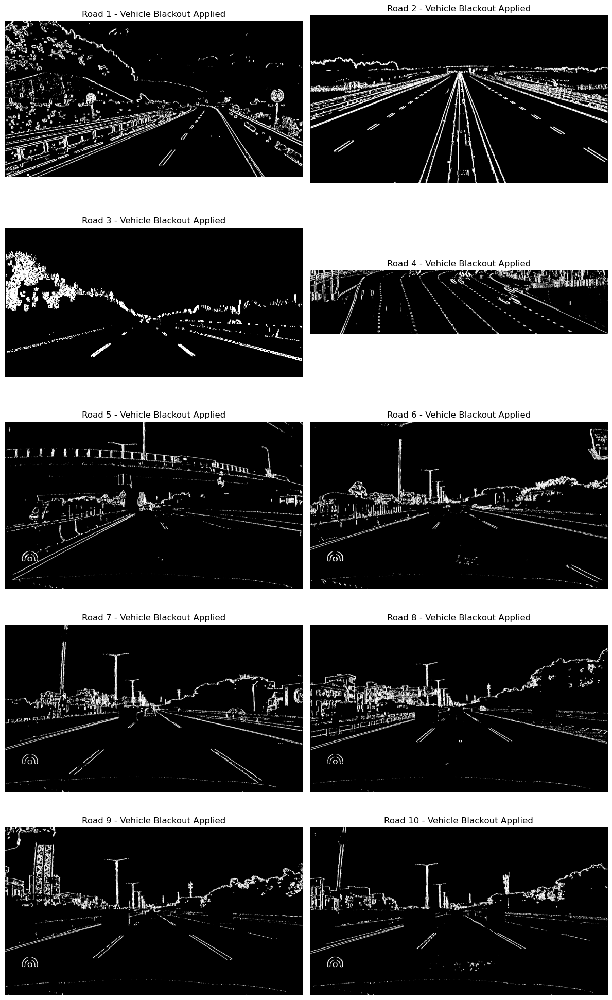

In [9]:
# Visualization of Vehicle Blackout Results
plt.figure(figsize=(12, 20))

for i, img in enumerate(images):
    # 1. Pre-processing chain
    rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    uniform_img = apply_clahe(rgb_img)
    
    # 2. Generate the initial combined mask
    if i < 4:  
        initial_mask = combined_color_gradient_mask(
            uniform_img, 
            sobel_thresh_min=10,
            white_l_min=150, 
            white_l_max=255, 
            white_s_min=0
        )
    else: 
        initial_mask = combined_color_gradient_mask(
            uniform_img, 
            sobel_thresh_min=7, 
            white_l_min=92, 
            white_l_max=255, 
            white_s_min=0
        )
    
    # 3. Convert mask to single channel (Grayscale) for the blackout function
    gray_mask = cv.cvtColor(initial_mask, cv.COLOR_RGB2GRAY)
    
    # 4. Apply Vehicle Blackout
    # Note: We pass uniform_img (color) for detection, but gray_mask for blackout
    final_mask = blackout_vehicles_from_mask(gray_mask, uniform_img, model)
    
    # Plotting
    plt.subplot(5, 2, i + 1)
    plt.imshow(final_mask, cmap='gray')
    plt.title(f'Road {i+1} - Vehicle Blackout Applied')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [10]:
def proportional_roi(canny_image, bottom_offset_left=300,bottom_offset_right=300, top_offset=0.45, top_width_factor_right=0.8, top_width_factor_left=0.20):
    # 1. Image Dimensions
    height, width = canny_image.shape[:2]
    
    # 2. Dynamic Trapezoid Coordinates
    bottom_left = (-bottom_offset_left, height)
    bottom_right = (width + bottom_offset_right, height)
    top_left = (int(width * top_width_factor_left), int(height * top_offset))
    top_right = (int(width * top_width_factor_right), int(height * top_offset))
    
    polygons = np.array([[bottom_left, top_left, top_right, bottom_right]], dtype=np.int32)
    
    # 3. Mask Generation & Application
    mask = np.zeros_like(canny_image)
    cv.fillPoly(mask, polygons, 255)
    masked_canny = cv.bitwise_and(canny_image, mask)
    
    return masked_canny

### Feature Extraction

In [11]:
def hough_lines(image, threshold=40, minLineLength=100, maxLineGap=35):
    # 1. Hough Space Resolution (Distance & Angle)
    rho = 1 
    theta = np.pi / 180 
    
    # 2. Probabilistic Hough Transform (Line Segment Detection)
    lines = cv.HoughLinesP(
        image, 
        rho, 
        theta, 
        threshold, 
        np.array([]), 
        minLineLength=minLineLength, 
        maxLineGap=maxLineGap
    )
    
    return lines

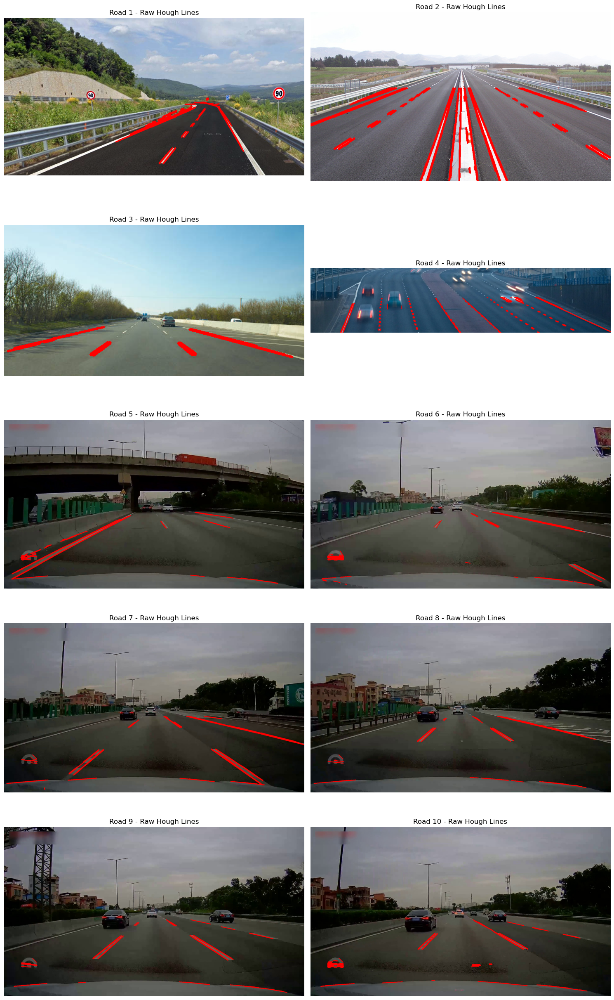

In [12]:
# Visualization of the Raw Hough Lines
plt.figure(figsize=(15, 25))

for i, img in enumerate(images):
    # 1. Pre-processing chain
    rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    uniform_img = apply_clahe(rgb_img)
    
    # 2. Generate the initial combined mask
    if i < 4:  # First 4 images (Roads 1 to 4)
        initial_mask = combined_color_gradient_mask(
            uniform_img, 
            sobel_thresh_min=10,
            white_l_min=150, 
            white_l_max=255, 
            white_s_min=0
        )
    else: # The rest of the images (Road 5+)
        initial_mask = combined_color_gradient_mask(
            uniform_img, 
            sobel_thresh_min=7, 
            white_l_min=92, 
            white_l_max=255, 
            white_s_min=0
        )
    
    # 3. Convert mask to Grayscale and Blackout Vehicles
    gray_mask = cv.cvtColor(initial_mask, cv.COLOR_RGB2GRAY)
    car_free_mask = blackout_vehicles_from_mask(gray_mask, uniform_img, model)
    
    # 4. Apply specific ROI based on the image index (i starts at 0 for Road 1)
    if i == 0:   # Road 1
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left=-200, bottom_offset_right=-200, top_offset=0.45, top_width_factor_right=0.7, top_width_factor_left=0.70)
    elif i == 1: # Road 2
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left=400, bottom_offset_right=400, top_offset=0.45, top_width_factor_right=0.75, top_width_factor_left=0.25)
    elif i == 2: # Road 3
        cropped_mask = proportional_roi(car_free_mask, top_offset=0.65, bottom_offset_left=100, bottom_offset_right=100, top_width_factor_right=0.6)
    elif i == 3: # Road 4
        cropped_mask = proportional_roi(car_free_mask)
    else:        # Road 5 and beyond
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left=500, bottom_offset_right=1000, top_offset=0.55, top_width_factor_right=0.70, top_width_factor_left=0.45)
    
    # 5. Apply Hough Transform
    if i < 4:
        lines = hough_lines(cropped_mask, threshold=35, minLineLength=6, maxLineGap=7)
    else:
        # Using the video parameters you tuned earlier for the rest
        lines = hough_lines(cropped_mask, threshold=50, minLineLength=12, maxLineGap=17) 
        
    # 6. Draw the RAW Hough Lines on the color image
    hough_display = rgb_img.copy()
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line[0]
            # Draw red lines (RGB format: 255 for Red channel)
            cv.line(hough_display, (int(x1), int(y1)), (int(x2), int(y2)), (255, 0, 0), 3)

    # 7. Plotting
    plt.subplot(5, 2, i + 1)
    plt.imshow(hough_display)
    plt.title(f'Road {i+1} - Raw Hough Lines')
    plt.axis('off')

plt.tight_layout()
plt.show()

In [13]:
def make_coordinates(image, line_parameters):    
    # 1. Parameter Unpacking
    slope, intercept, _ = line_parameters
    height, width = image.shape[:2]

    # 2. Invalid Slope Handling
    if slope is None or abs(slope) < 1e-3:
        return None

    # 3. Initial Coordinate Calculation
    y1 = height
    y2 = int(height * 0.70)
    x1 = (y1 - intercept) / slope
    x2 = (y2 - intercept) / slope

    # 4. Bottom Boundary Correction (Left/Right)
    if x1 < 0:
        x1 = 0
        y1 = slope * x1 + intercept
    elif x1 > width:
        x1 = width
        y1 = slope * x1 + intercept

    # 5. Top Boundary Correction
    if x2 < 0:
        x2 = 0
        y2 = slope * x2 + intercept
    elif x2 > width:
        x2 = width
        y2 = slope * x2 + intercept

    return np.array([int(x1), int(y1), int(x2), int(y2)])

### Clustering & Tracking

In [14]:
def merging_lines_dbscan(image, lines, MIN_DIST=300):
    """
    Groups individual Hough line segments into continuous lane candidates using DBSCAN clustering.
    It mathematically determines if a lane is 'solid' or 'dashed' and filters out duplicates.
    """
    if lines is None or len(lines) == 0: 
        return None
    
    height = image.shape[0]
    features = []
    valid_lines = []

    # ==========================================
    # 1. Feature Extraction (Angle & X-Bottom)
    # ==========================================
    # We extract two key features for clustering: the angle of the line and where it crosses the bottom of the screen.
    for line in lines:
        x1, y1, x2, y2 = line.reshape(4)
        
        # Handle vertical lines (x1 == x2) to prevent ZeroDivisionError when calculating slope.
        if abs(x2 - x1) < 1e-3:
            angle = np.pi / 2  
            slope = 9999.0     
            x_bottom = x1      
            intercept = y1 - slope * x1
        else:
            # Calculate standard line equation (y = mx + b) and the intersection at the bottom of the image (y = height).
            slope = (y2 - y1) / (x2 - x1)
            angle = np.arctan(slope) 
            intercept = y1 - slope * x1
            x_bottom = (height - intercept) / slope
        
        # Horizon Filter: Reject nearly horizontal lines (slope near 0)
        if abs(angle) < 0.20: 
            continue  

        length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        
        # Build the feature space for the clustering algorithm.
        features.append([angle, x_bottom])
        valid_lines.append({'slope': slope, 'intercept': intercept, 'length': length})
        
    if not features:
        return None

    # ==========================================
    # 2. Normalization & Weighting
    # ==========================================
    # Standardize features so they have a mean of 0 and variance of 1.
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    # Give 7x more weight to the X-Bottom position compared to the angle. 
    features_scaled[:, 1] *= 7.0

    # ==========================================
    # 3. DBSCAN Clustering
    # ==========================================
    # Groups lines that are spatially close and have similar angles into distinct lanes.
    dbscan = DBSCAN(eps=0.6, min_samples=2)
    clusters = dbscan.fit_predict(features_scaled)

    # ==========================================
    # 4. Process Clusters & Solid/Dashed Classification
    # ==========================================
    unique_clusters = set(clusters)
    lane_candidates = []
    
    for cluster_id in unique_clusters:
        # Ignore cluster '-1' as DBSCAN classifies it as outlier noise.
        if cluster_id == -1:
            continue 
            
        cluster_indices = np.where(clusters == cluster_id)[0]
        intervals = []
        max_single_length = 0
        
        # Find the "Reference Point" (the highest point visually on the screen for this cluster).
        # We will measure the distance of all line segments relative to this point.
        y_coords = [lines[i][0][1] for i in cluster_indices] + [lines[i][0][3] for i in cluster_indices]
        x_coords = [lines[i][0][0] for i in cluster_indices] + [lines[i][0][2] for i in cluster_indices]
        idx_min_y = np.argmin(y_coords)
    # ==========================================
        ref_x, ref_y = x_coords[idx_min_y], y_coords[idx_min_y]
        
        # Map 2D segments into a 1D distance interval [start_dist, end_dist].
        for i in cluster_indices:
            x1, y1, x2, y2 = lines[i][0]
            
            length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
            if length > max_single_length:
                max_single_length = length
                
            d1 = np.sqrt((x1 - ref_x)**2 + (y1 - ref_y)**2)
            d2 = np.sqrt((x2 - ref_x)**2 + (y2 - ref_y)**2)
            intervals.append([min(d1, d2), max(d1, d2)])
            
        # Sort intervals by starting point and merge any overlapping segments.
        # This prevents "double counting" paint when two bounding boxes cover the same physical line.
        intervals.sort(key=lambda x: x[0])
        merged = [intervals[0]]
        
        for current in intervals[1:]:
            previous = merged[-1]
            if current[0] <= previous[1]:
                previous[1] = max(previous[1], current[1]) # Extend existing interval
            else:
                merged.append(current) # Create new interval 
                
        # Calculate the total physical distance covered by the cluster vs how much paint was actually detected.
        paint_length = sum([end - start for start, end in merged])
        total_span = merged[-1][1] - merged[0][0]
        fill_ratio = paint_length / (total_span + 1e-5) # Prevent ZeroDivision
        
        safe_span = total_span if total_span > 0 else 1
        longest_chunk_ratio = max_single_length / safe_span
        
        
        # Classification Logic:
        # If > 90% of the lane boundary is painted, OR a single chunk covers > 80% of the view, classify as SOLID.
        line_type = "solid" if (fill_ratio > 0.90 or longest_chunk_ratio > 0.80) else "dashed"
            
        # The 'strength' is the total amount of unique paint found. Thicker/longer lines have higher strength.
        strength = paint_length
        avg_slope = np.mean([valid_lines[i]['slope'] for i in cluster_indices])
        avg_intercept = np.mean([valid_lines[i]['intercept'] for i in cluster_indices])
        avg_x_bottom = (height - avg_intercept) / avg_slope if avg_slope != 0 else 0
        
        lane_candidates.append({
            'slope': avg_slope,
            'intercept': avg_intercept,
            'x_bottom': avg_x_bottom,
            'strength': strength,
            'line_type': line_type 
        })

    # ==========================================
    # 5. Spatial NMS Filter (Non-Maximum Suppression)
    # ==========================================
    # Sort lanes by total paint length (most confident lines first).
    lane_candidates.sort(key=lambda x: x['strength'], reverse=True)
    filtered_lanes = []
    
    # Minimum horizontal pixel distance allowed between two lanes at the bottom of the screen.
    MIN_DIST = 250 

    for candidate in lane_candidates:
        too_close = False
        # Check against already accepted (stronger) lanes. If it's too close, it's likely a duplicate or noise.
        for accepted in filtered_lanes:
            if abs(candidate['x_bottom'] - accepted['x_bottom']) < MIN_DIST:
                too_close = True
                break
                
        if not too_close:
            filtered_lanes.append(candidate)

    # ==========================================
    # 6. Final Coordinates Attachment
    # ==========================================
    final_lanes_with_labels = []
    for lane in filtered_lanes:
        # Convert mathematical equations back to displayable pixel coordinates.
        coords = make_coordinates(image, (lane['slope'], lane['intercept'], None))
        if coords is not None:
            # Output structure: ((x1, y1, x2, y2), "solid" or "dashed")
            final_lanes_with_labels.append((coords, lane['line_type']))

    return final_lanes_with_labels if final_lanes_with_labels else None

/tmp/ipykernel_7850/1340501540.py:36: RuntimeWarning: divide by zero encountered in scalar divide
  x_bottom = (height - intercept) / slope


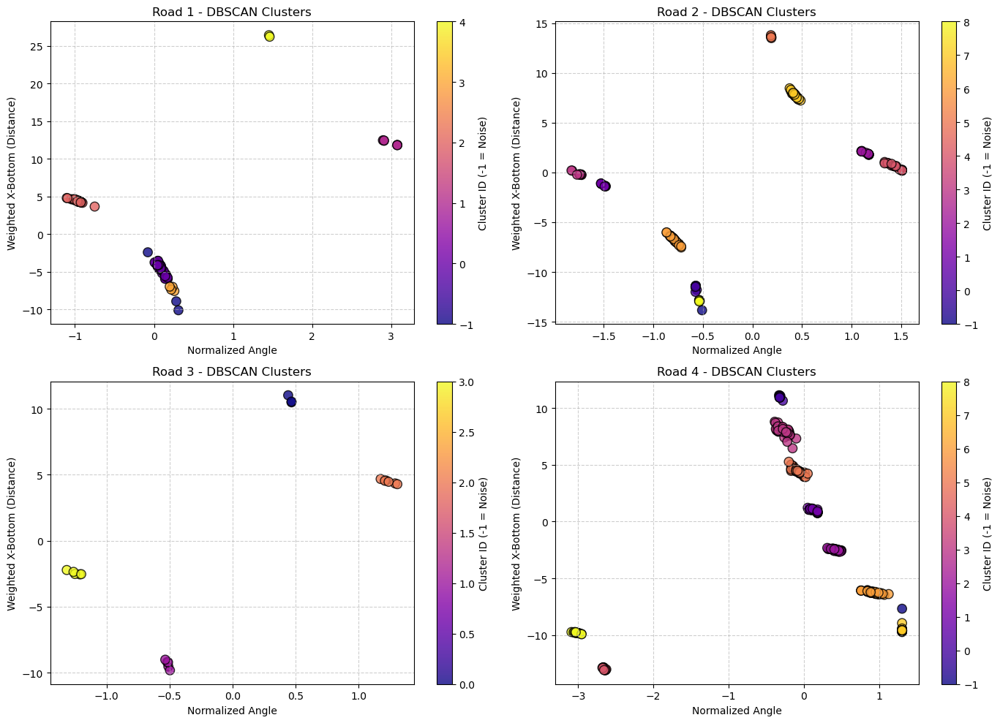

In [15]:
# visualzation of the DBSCAN Feature Space (Scatter Plots)
plt.figure(figsize=(14, 10))

for i, img in enumerate(images[:4]):
    # 1. Pre-processing & ROI (Same as before)
    rgb_img = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    uniform_img = apply_clahe(rgb_img)
    initial_mask = combined_color_gradient_mask(uniform_img, sobel_thresh_min=10, white_l_min=150, white_l_max=255, white_s_min=0)
    gray_mask = cv.cvtColor(initial_mask, cv.COLOR_RGB2GRAY)
    car_free_mask = blackout_vehicles_from_mask(gray_mask, uniform_img, model)
    
    if i == 0:
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left=-200, bottom_offset_right=-200, top_offset=0.45, top_width_factor_right=0.7, top_width_factor_left=0.70)
    elif i == 1:
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left=400, bottom_offset_right=400, top_offset=0.45, top_width_factor_right=0.75, top_width_factor_left=0.25)
    elif i == 2:
        cropped_mask = proportional_roi(car_free_mask, top_offset=0.65, bottom_offset_left=100, bottom_offset_right=100, top_width_factor_right=0.6)
    elif i == 3:
        cropped_mask = proportional_roi(car_free_mask)
        
    lines = hough_lines(cropped_mask, threshold=35, minLineLength=6, maxLineGap=7)
    
    # 2. Extract Features (Angle & X-Bottom) manually for plotting
    height = img.shape[0]
    features = []
    
    if lines is not None:
        for line in lines:
            x1, y1, x2, y2 = line.reshape(4)
            if abs(x2 - x1) < 1e-3:
                angle, slope, x_bottom = np.pi / 2, 9999.0, x1
            else:
                slope = (y2 - y1) / (x2 - x1)
                angle = np.arctan(slope) 
                intercept = y1 - slope * x1
                x_bottom = (height - intercept) / slope
            
            if abs(angle) >= 0.20: # Horizon Filter
                features.append([angle, x_bottom])
    
    # 3. Plotting the Scatter Graph
    plt.subplot(2, 2, i + 1)
    
    if len(features) > 0:
        # Scale and Weight features just like the main function
        scaler = StandardScaler()
        features_scaled = scaler.fit_transform(features)
        features_scaled[:, 1] *= 7.0 
        
        # Cluster
        dbscan = DBSCAN(eps=0.6, min_samples=2)
        clusters = dbscan.fit_predict(features_scaled)
        
        # Scatter Plot (Color-coded by cluster ID)
        scatter = plt.scatter(features_scaled[:, 0], features_scaled[:, 1], 
                              c=clusters, cmap='plasma', s=80, edgecolors='k', alpha=0.8)
        plt.colorbar(scatter, label='Cluster ID (-1 = Noise)')
        
    plt.title(f'Road {i+1} - DBSCAN Clusters')
    plt.xlabel('Normalized Angle')
    plt.ylabel('Weighted X-Bottom (Distance)')
    plt.grid(True, linestyle='--', alpha=0.6)
    #plt.savefig('scatter_plot.png', dpi=300, bbox_inches='tight')

plt.tight_layout()
plt.show()

In [16]:
def merging_lines_video(image, lines, lane_memory, MAX_SLOPE=6.0):
    """
    Advanced video lane tracking algorithm.
    It clusters raw Hough lines, classifies them (solid/dashed), resolves spatial conflicts 
    (preventing crossed lines), and uses temporal memory (EMA) to smooth movement across frames.
    """
    if lines is None or len(lines) == 0: 
        return None
    
    height = image.shape[0]
    width = image.shape[1]
    features = []
    valid_lines = []

    # ==========================================
    # 1. Feature Extraction & Zero-Division Protection
    # ==========================================
    # Convert arbitrary line segments into robust mathematical models (Angle and X-Intercept).
    for line in lines:
        x1, y1, x2, y2 = line.reshape(4)
        
        # Guard against perfectly vertical lines causing division-by-zero in slope calculation
        if abs(x2 - x1) < 1e-3:
            angle = np.pi / 2  
            slope = 9999.0     
            intercept = x1
        else:
            slope = (y2 - y1) / (x2 - x1)
            angle = np.arctan(slope) 
            intercept = y1 - slope * x1
            
        # Reject highly distorted lines (extreme slopes) and flat horizontal lines (horizon/shadows)
        if abs(slope) > MAX_SLOPE or abs(angle) < 0.20: 
            continue  

        # Calculate exactly where this line intersects the bottom edge of the image (y = height)
        x_bottom = (height - intercept) / slope
        length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        
        features.append([angle, x_bottom])
        valid_lines.append({'slope': slope, 'intercept': intercept, 'length': length, 'x_bottom': x_bottom})
        
    if not features: 
        return None

    # ==========================================
    # 2. DBSCAN Clustering & Normalization
    # ==========================================
    scaler = StandardScaler()
    features_scaled = scaler.fit_transform(features)
    
    # Weighting: Multiply the X-Bottom feature by 7 to make spatial position much more 
    features_scaled[:, 1] *= 7.0

    dbscan = DBSCAN(eps=0.6, min_samples=2)
    clusters = dbscan.fit_predict(features_scaled)

    # ==========================================
    # 3. Cluster Processing & Classification (Solid/Dashed)
    # ==========================================
    unique_clusters = set(clusters)
    lane_candidates = []
    
    for cluster_id in unique_clusters:
        if cluster_id == -1: # Ignore noise/outliers identified by DBSCAN
            continue 
            
        cluster_indices = np.where(clusters == cluster_id)[0]
        intervals = []
        max_single_length = 0
        
        # Determine the visual "top" of the cluster to act as a 0-point reference for distance calculations
        y_coords = [lines[i][0][1] for i in cluster_indices] + [lines[i][0][3] for i in cluster_indices]
        x_coords = [lines[i][0][0] for i in cluster_indices] + [lines[i][0][2] for i in cluster_indices]
        idx_min_y = np.argmin(y_coords)
        ref_x, ref_y = x_coords[idx_min_y], y_coords[idx_min_y]
        
        # Convert 2D segments into 1D distance intervals from the reference point
        for i in cluster_indices:
            x1, y1, x2, y2 = lines[i][0]
            length = np.sqrt((x2 - x1)**2 + (y2 - y1)**2)
            if length > max_single_length: 
                max_single_length = length
                
            d1 = np.sqrt((x1 - ref_x)**2 + (y1 - ref_y)**2)
            d2 = np.sqrt((x2 - ref_x)**2 + (y2 - ref_y)**2)
            intervals.append([min(d1, d2), max(d1, d2)])
            
        # Merge overlapping intervals to ensure we don't double-count paint in the exact same spot
        intervals.sort(key=lambda x: x[0])
        merged = [intervals[0]]
        
        for current in intervals[1:]:
            previous = merged[-1]
            if current[0] <= previous[1]:
                previous[1] = max(previous[1], current[1])
            else:
                merged.append(current) 
                
        # Calculate how much of the lane boundary is actually covered in paint (Fill Ratio)
        paint_length = sum([end - start for start, end in merged])
        total_span = merged[-1][1] - merged[0][0]
        fill_ratio = paint_length / (total_span + 1e-5) 
        safe_span = total_span if total_span > 0 else 1
        longest_chunk_ratio = max_single_length / safe_span

        
        # Classification: Considered 'solid' if >90% is painted OR a single unbroken block covers >80%
        #line_type = "solid" if (fill_ratio > 0.85 or longest_chunk_ratio > 0.80) else "dashed"
        line_type = "solid" if (fill_ratio > 0.85 and longest_chunk_ratio > 0.55) else "dashed"
            
        # Aggregate the final properties of this lane candidate
        avg_slope = np.mean([valid_lines[i]['slope'] for i in cluster_indices])
        avg_intercept = np.mean([valid_lines[i]['intercept'] for i in cluster_indices])
        avg_x_bottom = np.mean([valid_lines[i]['x_bottom'] for i in cluster_indices])
        
        lane_candidates.append({
            'slope': avg_slope,
            'intercept': avg_intercept,
            'x_bottom': avg_x_bottom,
            'strength': paint_length,
            'line_type': line_type 
        })

    # ==========================================
    # 4. Spatial NMS Filter (Center-Seeking Conflict Resolution)
    # ==========================================
    if not lane_candidates:
        return None

    center_x = width / 2
    MIN_LANE_WIDTH = 450 
    to_delete = set()

    for i in range(len(lane_candidates)):
        if i in to_delete: continue
        for j in range(i + 1, len(lane_candidates)):
            if j in to_delete: continue

            c1, c2 = lane_candidates[i], lane_candidates[j]
            
            # Distance at the bottom of the screen (bumper level)
            dist_bot = abs(c1['x_bottom'] - c2['x_bottom'])

            # Distance at 80% down the screen (prevents deleting lanes that just look narrow in the distance)
            y_mid = height * 0.80 
            x1_mid = (y_mid - c1['intercept']) / c1['slope'] if c1['slope'] != 9999.0 else c1['x_bottom']
            x2_mid = (y_mid - c2['intercept']) / c2['slope'] if c2['slope'] != 9999.0 else c2['x_bottom']
            dist_mid = abs(x1_mid - x2_mid)

            # Calculate mathematical intersection point (y_cross) of the two lines
            y_cross = -1
            if c1['slope'] == 9999.0:
                y_cross = c2['slope'] * c1['x_bottom'] + c2['intercept']
            elif c2['slope'] == 9999.0:
                y_cross = c1['slope'] * c2['x_bottom'] + c1['intercept']
            elif abs(c1['slope'] - c2['slope']) > 1e-4:
                x_cross = (c2['intercept'] - c1['intercept']) / (c1['slope'] - c2['slope'])
                y_cross = c1['slope'] * x_cross + c1['intercept']

            # Conflict triggers if lines are too close at bottom/mid, OR if they physically cross in the bottom 35% of view
            is_conflict = (dist_bot < MIN_LANE_WIDTH) or (dist_mid < 60) or (y_cross > height * 0.65)
          
            if is_conflict:
                # Priority to steeper slopes (Real Lanes) over flat walls
                # OR stick to center-seeking if slopes are similar
                slope_i = abs(c1['slope'])
                slope_j = abs(c2['slope'])

                # If one is significantly steeper, it's likely the real lane
                if abs(slope_i - slope_j) > 0.5:
                    if slope_i > slope_j:
                        to_delete.add(j) # Keep steeper (i)
                    else:
                        to_delete.add(i) # Keep steeper (j)
                        break
                else:
                    # Fallback to center-seeking if slopes are almost the same
                    dist_to_center1 = abs(c1['x_bottom'] - center_x)
                    dist_to_center2 = abs(c2['x_bottom'] - center_x)
                    if dist_to_center1 < dist_to_center2:
                        to_delete.add(j)
                    else:
                        to_delete.add(i)
                        break

    filtered_candidates = [cand for i, cand in enumerate(lane_candidates) if i not in to_delete]
    filtered_candidates.sort(key=lambda x: x['strength'], reverse=True)
    filtered_candidates = filtered_candidates[:3]

    # ==========================================
    # 5. Temporal Video Memory (Tracker & Smoother)
    # ==========================================
    # Reset match status for the new frame
    for memory in lane_memory:
        memory['matched_this_frame'] = False

    for candidate in filtered_candidates:
        best_match = None
        min_diff = 150 # Maximum pixel distance a line can jump between consecutive frames
        
        # Find the closest existing lane in memory to this new candidate
        for memory in lane_memory:
            if not memory['matched_this_frame']:
                diff = abs(candidate['x_bottom'] - memory['x_bottom'])
                if diff < min_diff:
                    best_match = memory
                    min_diff = diff
                    
        if best_match is not None:
            # Match Found! Apply Exponential Moving Average (EMA) to smooth the line tracking.
            # 80% weight to historical data, 20% weight to the new frame. Prevents jittering.
            if abs(best_match['lane']['slope']) < 1000 and abs(candidate['slope']) < 1000:
                best_match['lane']['slope'] = 0.8 * best_match['lane']['slope'] + 0.2 * candidate['slope']
                best_match['lane']['intercept'] = 0.8 * best_match['lane']['intercept'] + 0.2 * candidate['intercept']
            
            # Update trackers
            best_match['x_bottom'] = candidate['x_bottom'] 
            best_match['hits'] += 1
            best_match['misses'] = 0
            best_match['matched_this_frame'] = True
            
            # Voting system for line classification to prevent flickering between solid and dashed
            best_match['type_history'].append(candidate['line_type'])
            if len(best_match['type_history']) > 15:
                best_match['type_history'].pop(0)
                
            solid_votes = best_match['type_history'].count('solid')
            dashed_votes = best_match['type_history'].count('dashed')
            best_match['lane']['line_type'] = 'solid' if solid_votes >= dashed_votes else 'dashed'
        else:
            # No match found. Register this as a completely new lane in memory.
            lane_memory.append({
                'x_bottom': candidate['x_bottom'],
                'hits': 1,
                'misses': 0,
                'lane': candidate,
                'matched_this_frame': True,
                'type_history': [candidate['line_type']] 
            })

    # ==========================================
    # 6. Coordinate Generation & Lifecycle Management
    # ==========================================
    final_lanes_with_labels = []
    
    for memory in lane_memory[:]: 
        if not memory['matched_this_frame']:
            memory['misses'] += 1 # Penalize lanes that vanished in this frame
            
        # If a lane goes missing for > 5 consecutive frames, delete it from memory
        if memory['misses'] > 5: 
            lane_memory.remove(memory)
        # Only draw lanes that have been consistently seen for at least 2 frames (prevents 1-frame ghost flashes)
        elif memory['hits'] >= 3: 
            coords = make_coordinates(image, (memory['lane']['slope'], memory['lane']['intercept'], None))
            if coords is not None:
                final_lanes_with_labels.append((coords, memory['lane']['line_type']))

    return final_lanes_with_labels if final_lanes_with_labels else None

### Visualization

In [17]:
def display_lines(image, average_lines_with_labels):
    # 1. Blank Canvas Initialization
    line_image = np.zeros_like(image)
    
    if average_lines_with_labels is not None:
        for coords, line_type in average_lines_with_labels:
            # 2. Coordinate Extraction
            x1, y1, x2, y2 = coords
            
            # 3. Dynamic Color Mapping (Red=Solid, Blue=Dashed)
            color = (0, 0, 255) if line_type == "solid" else (255, 0, 0)
                
            # 4. Render Line and Text Overlay
            cv.line(line_image, (int(x1), int(y1)), (int(x2), int(y2)), color, thickness=10)
            cv.putText(line_image, line_type.upper(), (int(x1) - 20, int(y1) - 20), 
                       cv.FONT_HERSHEY_SIMPLEX, 1, color, 3, cv.LINE_AA)
            
    return line_image

In [18]:
def draw_lane_area(sampling_image, background_image, average_lines_with_labels, color=(0, 255, 0), alpha=0.3, color_tolerance = 35 ):
    """
    Highlights the drivable area between lane lines.
    Uses color-sampling to ensure the space between lines is actual road (asphalt) 
    and not a sidewalk or barrier.
    """
    if average_lines_with_labels is None or len(average_lines_with_labels) < 2:
        return background_image
        
    # 1. Overlay Initialization
    overlay = np.zeros_like(background_image)
    height, width = background_image.shape[:2]
    
    # 2. Extract and Sort Coordinates
    # We only need the coordinates, not the "solid/dashed" labels for this part.
    just_coords = [lane[0] for lane in average_lines_with_labels]
    
    def get_raw_x_bottom(line):
        x1, y1, x2, y2 = line
        if x2 == x1: return x1 
        
        slope = (y2 - y1) / (x2 - x1)
        
        if abs(slope) < 0.001: 
            return x1
            
        return x1 + (height - y1) / slope

    # Sort lines from left to right based on their starting point at the bottom of the screen.
    sorted_lines = sorted(just_coords, key=get_raw_x_bottom)
    
    candidates = []
    
    # 3. Polygon Generation and Color Sampling
    # Look at every adjacent pair of lines to form a trapezoid (potential lane).
    for i in range(len(sorted_lines) - 1):
        line_left = sorted_lines[i]
        line_right = sorted_lines[i + 1]
        
        _, _, x2_l, y2_l = line_left
        _, _, x2_r, y2_r = line_right
        
        raw_x_bottom_left = get_raw_x_bottom(line_left)
        raw_x_bottom_right = get_raw_x_bottom(line_right)
        
        # Build the 4 corners of the trapezoid between the two lines.
        polygon_points = np.array([[
            [int(raw_x_bottom_left), height],
            [int(x2_l), int(y2_l)],
            [int(x2_r), int(y2_r)],
            [int(raw_x_bottom_right), height]
        ]], np.int32)
        
        # Create a temporary mask to isolate just the pixels inside this trapezoid.
        mask = np.zeros(sampling_image.shape[:2], dtype=np.uint8)
        cv.fillPoly(mask, [polygon_points], 255)
        
        # Calculate the average (mean) BGR color of the pixels inside this trapezoid using the sampling image.
        mean_color = cv.mean(sampling_image, mask=mask)[:3] 
        
        candidates.append({
            'polygon': polygon_points,
            'mean_color': np.array(mean_color) 
        })

    # 4. Color Outlier Rejection
    if len(candidates) == 1:
        # If there's only one lane, we assume it's valid and draw it.
        cv.fillPoly(overlay, [candidates[0]['polygon']], color)
        
    elif len(candidates) > 1:
        # If there are multiple lanes, find the "median" color of all lanes.
        # This acts as our "true asphalt color" baseline.
        all_colors = [cand['mean_color'] for cand in candidates]
        reference_color = np.median(all_colors, axis=0)
        
        for cand in candidates:
            # Measure the Euclidean distance between this lane's color and the reference color.
            color_distance = np.linalg.norm(cand['mean_color'] - reference_color)
            
            # If the color is similar to asphalt, color it green.
            # If it's too different (like grass or a white barrier), ignore it.
            if color_distance < color_tolerance:
                cv.fillPoly(overlay, [cand['polygon']], color)
                
    # 5. Final Blending
    # Blend the semi-transparent green overlay onto the original real-world image.
    blended_image = cv.addWeighted(background_image, 1.0, overlay, alpha, 0)
    
    return blended_image

In [19]:
def analyze_traffic_and_alarms(raw_image, lane_image, yolo_model, lines_with_labels):
    annotated_image = lane_image.copy()
    height, width = raw_image.shape[:2]
    
    # 1. YOLO Object Detection (Vehicles Only)
    results = yolo_model.predict(raw_image, classes=[2, 3, 5, 7], conf=0.30, verbose=False)
    has_lanes = lines_with_labels is not None and len(lines_with_labels) >= 2
    
    line_equations = []
    Main_lane_index = -1
    
    # 2. Lane Equation Extraction & Main Lane Identification
    if has_lanes:
        for coords, line_type in lines_with_labels:
            x1, y1, x2, y2 = coords
            
            # Vertical & Horizontal Line Protection (Prevent Math Crashes)
            if abs(x2 - x1) < 1e-3:
                slope, intercept, x_bottom = 9999.0, x1, x1
            else:
                slope = (y2 - y1) / (x2 - x1)
                intercept = y1 - slope * x1
                x_bottom = x1 if abs(slope) < 1e-4 else (height - intercept) / slope
                
            line_equations.append({'slope': slope, 'intercept': intercept, 'x_bottom': x_bottom})
            
        line_equations.sort(key=lambda x: x['x_bottom'])
        
        # Define Main Lane based on Screen Center
        center_x = width / 2
        for i in range(len(line_equations) - 1):
            if line_equations[i]['x_bottom'] <= center_x <= line_equations[i+1]['x_bottom']:
                Main_lane_index = i
                break
                
    # 3. Target Position Analysis
    for result in results:
        for box in result.boxes:
            x1, y1, x2, y2 = box.xyxy[0].int().tolist()
            class_name = yolo_model.names[int(box.cls[0].item())]
            
            # Bottom Center of the Bounding Box (Tire Contact Point)
            cx = int((x1 + x2) / 2)
            cy = y2 
            is_dangerously_close = (cy > height * 0.75)
            
            # Default State
            box_color = (255, 255, 255) 
            label = f"{class_name} (No Lane Data)"
            
            if has_lanes:
                car_lane_index = -1
                
                # 4. Target Lane Assignment
                for i in range(len(line_equations) - 1):
                    m_l, b_l = line_equations[i]['slope'], line_equations[i]['intercept']
                    m_r, b_r = line_equations[i+1]['slope'], line_equations[i+1]['intercept']
                    
                    # Safe X calculation at bounding box Y-level
                    x_l = line_equations[i]['x_bottom'] if abs(m_l) > 1000 or abs(m_l) < 1e-4 else (cy - b_l) / m_l
                    x_r = line_equations[i+1]['x_bottom'] if abs(m_r) > 1000 or abs(m_r) < 1e-4 else (cy - b_r) / m_r
                    
                    if min(x_l, x_r) <= cx <= max(x_l, x_r):
                        car_lane_index = i
                        break
                
                # 5. Dynamic Alarms (Main + Adjacent Lanes Logic)
                # Check if the car is in our lane OR immediately left/right of us
                is_adjacent = (Main_lane_index != -1) and (abs(car_lane_index - Main_lane_index) <= 1)
                
                if car_lane_index == -1:
                    box_color, label = (255, 255, 255), f"{class_name} (Out of bounds)"
                elif is_adjacent and is_dangerously_close:
                    box_color, label = (0, 0, 255), f"ALARM: {class_name.upper()} TOO CLOSE!"
                elif car_lane_index == Main_lane_index:
                    box_color, label = (0, 165, 255), f"{class_name} (Main Lane)"
                else:
                    box_color, label = (0, 255, 0), f"{class_name} (Lane {car_lane_index})"
                    
            # 6. UI Rendering (HUD Overlay)
            cv.rectangle(annotated_image, (x1, y1), (x2, y2), box_color, 2)
            (text_w, text_h), _ = cv.getTextSize(label, cv.FONT_HERSHEY_SIMPLEX, 0.5, 2)
            cv.rectangle(annotated_image, (x1, y1 - 20), (x1 + text_w, y1), box_color, -1)
            text_color = (0, 0, 0) if box_color in [(255, 255, 255), (0, 255, 255)] else (255, 255, 255)
            cv.putText(annotated_image, label, (x1, y1 - 5), cv.FONT_HERSHEY_SIMPLEX, 0.5, text_color, 2)
            cv.circle(annotated_image, (cx, cy), 6, box_color, -1)
            
    return annotated_image

In [20]:
def check_lane_crossing(image, average_lines, margin=100):
    """
    Detects if the vehicle is drifting too close to a lane line.
    margin: The critical distance (in pixels) from the center of the car to the lane.
    """
    warning_overlay = np.zeros_like(image)
    
    if average_lines is None:
        return warning_overlay
        
    height, width = image.shape[:2]
    center_x = width // 2  # The center of the camera/car
    
    alert_triggered = False
    message = ""

    for coords, line_type in average_lines:
        x1, y1, x2, y2 = coords
        
        # Calculate how far the bottom of the lane is from the center of the car
        distance_to_center = x1 - center_x
        
        # Left Lane Check (x1 is to the left of the center, so distance is negative)
        if distance_to_center < 0 and abs(distance_to_center) < margin:
            message = "WARNING: LEFT LANE DRIFT!"
            alert_triggered = True
            
        # Right Lane Check (x1 is to the right of the center, so distance is positive)
        elif distance_to_center > 0 and abs(distance_to_center) < margin:
            message = "WARNING: RIGHT LANE DRIFT!"
            alert_triggered = True

    # If an alert is triggered, draw a flashing red UI banner
    if alert_triggered:
        # Draw a semi-transparent red banner at the top of the screen
        cv.rectangle(warning_overlay, (0, 0), (width, 80), (0, 0, 255), -1)
        
        # Add the warning text
        text_size = cv.getTextSize(message, cv.FONT_HERSHEY_DUPLEX, 1.2, 3)[0]
        text_x = (width - text_size[0]) // 2
        cv.putText(warning_overlay, message, (text_x, 55), 
                   cv.FONT_HERSHEY_DUPLEX, 1.2, (255, 255, 255), 3, cv.LINE_AA)
                   
    return warning_overlay

### Final Testing

[ WARN:0@44.544] global loadsave.cpp:278 findDecoder imread_('roads/road1.jpg'): can't open/read file: check file path/integrity
/tmp/ipykernel_7850/656404550.py:31: RuntimeWarning: divide by zero encountered in scalar divide
  x_bottom = (height - intercept) / slope
[ WARN:0@45.287] global loadsave.cpp:278 findDecoder imread_('roads/road4.jpg'): can't open/read file: check file path/integrity


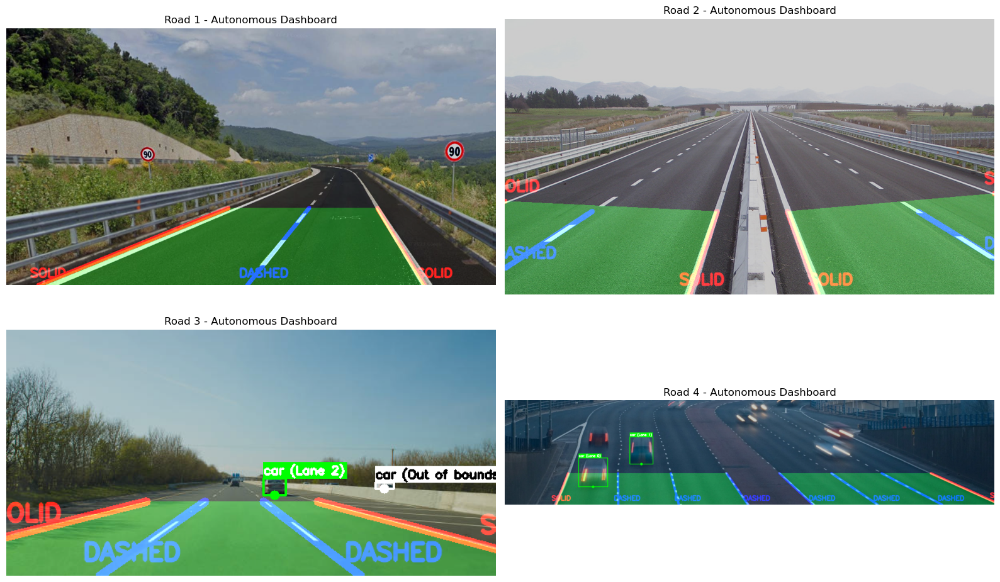

In [21]:
# Create a 2x2 grid to show the Final Resultsfor all 4 images
plt.figure(figsize=(16, 10))

for i in range(1, 5):
    road = cv.imread(f'roads/road{i}.jpg') 
    if road is None:
        road = cv.imread(f'roads/road{i}.png') 
        if road is None:
            print(f"Error loading image roads/road{i}.jpg or roads/road{i}.png")
            continue
            
    uniform_road = apply_clahe(road)
    
    masked_road = combined_color_gradient_mask(
        uniform_road, 
        sobel_thresh_min=10,
        white_l_min=150, 
        white_l_max=255, 
        white_s_min=0
    )

    gray_mask = cv.cvtColor(masked_road, cv.COLOR_BGR2GRAY)
    car_free_mask = blackout_vehicles_from_mask(gray_mask, road, model)

    if i == 1:
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left = -200, bottom_offset_right = -200, top_offset=0.45, top_width_factor_right=0.7, top_width_factor_left=0.70)
    elif i == 2:
        cropped_mask = proportional_roi(car_free_mask, bottom_offset_left =400, bottom_offset_right=400, top_offset=0.45, top_width_factor_right=0.75, top_width_factor_left=0.25)
    elif i == 3:
        cropped_mask = proportional_roi(car_free_mask, top_offset=0.65, bottom_offset_left= 100, bottom_offset_right=100, top_width_factor_right=0.6)
    else:
        cropped_mask = proportional_roi(car_free_mask)
    
    lines = hough_lines(cropped_mask, threshold=35, minLineLength=6, maxLineGap=7)

    average_lines = merging_lines_dbscan(road, lines)
    line_image = display_lines(road, average_lines)
      
    combo_image = cv.addWeighted(road, 0.8, line_image, 1, 1)
    final_output = draw_lane_area(uniform_road, combo_image, average_lines)

    annotated_output = analyze_traffic_and_alarms(road, final_output, model, average_lines)

    annotated_rgb = cv.cvtColor(annotated_output, cv.COLOR_BGR2RGB)
    
    plt.subplot(2, 2, i)
    plt.imshow(annotated_rgb)
    plt.title(f'Road {i} - Autonomous Dashboard')
    plt.axis('off')
    #plt.savefig('finalResults.png', dpi=300, bbox_inches='tight')


plt.tight_layout()
plt.show()


### Final Video Output

Note: If you prefer to see the final result without running the code, the pre-processed output video is included in the project directory. Please check the file named **`finalResultOnVideo.mp4`** in the report folder to watch the fully rendered output.


In [22]:
# testing the code on a video
cap = cv.VideoCapture('roads/video1.mp4')

# ==========================================

# ---> CREATE THE MEMORY BANK HERE <---
global_lane_memory = []

cv.namedWindow('Autonomous Dashboard', cv.WINDOW_NORMAL)
cv.setWindowProperty('Autonomous Dashboard', cv.WND_PROP_FULLSCREEN, cv.WINDOW_FULLSCREEN)

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break
        
    uniform_road = apply_clahe(frame)
    
    # Using your baseline tuned mask parameters here. 
    masked_road = combined_color_gradient_mask(
        uniform_road, 
        sobel_thresh_min=7, 
        white_l_min=92, 
        white_l_max=255, 
        white_s_min=0
    )

    # Convert to single-channel Grayscale for the Hough Transform
    gray_mask = cv.cvtColor(masked_road, cv.COLOR_BGR2GRAY)

    car_free_mask = blackout_vehicles_from_mask(gray_mask, frame, model)
    cropped_mask = proportional_roi(car_free_mask, bottom_offset_left=100, bottom_offset_right=1000, top_offset=0.55, top_width_factor_right=0.70, top_width_factor_left=0.45)
    
    lines = hough_lines(cropped_mask, threshold=50, minLineLength=12, maxLineGap=17)

    raw_hough_display = frame.copy()
    if lines is not None: 
        for line in lines:
            x1, y1, x2, y2 = line[0]
            # Draw thin red lines directly onto the copy
            cv.line(raw_hough_display, (int(x1), int(y1)), (int(x2), int(y2)), (0, 0, 255), 2)

    average_lines = merging_lines_video(frame, lines, global_lane_memory)
    line_image = display_lines(frame, average_lines)
    
    # Calculate Lane Departure Warning Overlay
    ldw_overlay = check_lane_crossing(frame, average_lines, margin=150)
    
    # Blend the normal lines, then blend the red warning banner on top
    combo_image = cv.addWeighted(frame, 0.8, line_image, 1, 1)
    combo_image = cv.addWeighted(combo_image, 1.0, ldw_overlay, 1.0, 0) 
    
    final_output = draw_lane_area(uniform_road, combo_image, average_lines, color_tolerance=60)

    annotated_output = analyze_traffic_and_alarms(frame, final_output, model, average_lines)
    
    cv.putText(
    annotated_output,
    "Press Q to quit",
    (20, 40),  
    cv.FONT_HERSHEY_SIMPLEX,
    1,
    (255, 255, 255),
    2,
    cv.LINE_AA
    )
    
    cv.imshow('Autonomous Dashboard', annotated_output)

    if cv.waitKey(1) & 0xFF == ord('q'):
        break
        
cap.release()
cv.destroyAllWindows()